# Inteligência de Risco e Clusterização de Fraudes — Arquétipos de Ataque

Enquanto a modelagem supervisionada (`02_Modelagem.ipynb`) responde **qual a probabilidade** de uma transação ser fraudulenta, este notebook responde a pergunta estratégica da área de Risco: **"Quem são e como operam as quadrilhas por trás das fraudes?"**

Para que a variância dos 96,5% de compradores legítimos não esmague os padrões específicos dos atacantes, isolamos **100% das transações fraudulentas confirmadas (`isFraud == 1`)** para diagnóstico de negócio.

## Estrutura da Esteira de Clusterização:
1. **Configuração, Escopo Temporal e Filtragem:** Carregamento de `df_master.parquet` e isolamento exclusivo de `isFraud == 1` ordenado por `TransactionDT`.
2. **Seleção de Features, Saneamento e Escala:** Remoção de IDs arbitrários, ancoragem de drift em `D1..D15`, encoding misto (OHE + Frequency Encoding), `log1p` e `RobustScaler`.
3. **Redução de Dimensionalidade (PCA vs. UMAP):** Projeção base em **10D** para clusterizar (`X_pca_10d`, `X_umap_10d`) e projeção **2D** separada apenas para inspeção visual (`X_umap_2d`).
4. **Baseline Particional (K-Means):** Varredura de $K \in [2, 12]$ em PCA 10D e UMAP 10D (Elbow, Silhouette em **subsample de 10.000 pontos (10k)**, Davies-Bouldin e Calinski-Harabasz).
5. **Modelo Final (K-Means K=10), Perfilamento e Assinatura das Quadrilhas:** Treinamento final em `X_umap_10d`, tabela executiva de impacto financeiro/operacional, volumetria, mapa UMAP 2D (**subsample visual de 15k**) e Heatmap de Z-Score.

---
## 1.0 Configuração do Ambiente, Escopo Temporal e Filtragem

- **Regra de ouro:** nunca misturar `isFraud == 0` nesta etapa, pois a massa legítima dominaria os componentes do PCA e a topologia do UMAP.
- **Recorte escolhido:** Diagnóstico de Negócio completo utilizando **100% das fraudes** do `df_master.parquet` (~20,6k registros).
- **Política de Subsample (documentada):**
  - **Silhouette Score:** `subsample = 10.000 (10k)` pontos na varredura do K-Means, nos *trials* do Optuna e na tabela comparativa final (reduz custo $O(n^2)$ mantendo precisão estatística).
  - **Scatter Plotly 2D:** `subsample = 15.000 (15k)` pontos para manter renderização fluida no navegador.

> **Instalação de Pacotes (se necessário no Colab):**
> `!pip install -q umap-learn hdbscan plotly optuna`

In [68]:
# ==============================================================================
# 1.0 CONFIGURAÇÃO DO AMBIENTE E IMPORTS
# ==============================================================================
import os
import sys
import json
import warnings
import importlib
from pathlib import Path

warnings.filterwarnings('ignore')

# Resolução robusta da raiz do projeto (Local ou Google Colab)
current_dir = Path(os.getcwd()).resolve()
if (current_dir / 'utils.py').exists():
    PROJECT_ROOT = current_dir
elif (current_dir.parent / 'utils.py').exists():
    PROJECT_ROOT = current_dir.parent
elif (current_dir.parent.parent / 'utils.py').exists():
    PROJECT_ROOT = current_dir.parent.parent
else:
    PROJECT_ROOT = current_dir

os.chdir(PROJECT_ROOT)
for p in [str(PROJECT_ROOT), os.path.abspath('.'), os.path.abspath('..')]:
    if p not in sys.path:
        sys.path.append(p)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.cluster import KMeans

import utils
importlib.reload(utils)
from utils import (
    preparar_dados_clusterizacao,
    projetar_pca,
    plot_pca_variancia_acumulada,
    projetar_umap,
    avaliar_kmeans_range,
    plot_elbow_comparativo,
    plot_metricas_validacao,
    plot_distribuicao_clusters,
    plot_clusters_2d_plotly,
    gerar_perfil_fraude_clusters,
    plot_heatmap_zscore_clusters,
)

RANDOM_STATE = 42

# Subsamples explícitos para desempenho e fluidez visual:
# - 10.000 (10k) no Silhouette Score (varredura do K-Means)
# - 15.000 (15k) no scatter interativo Plotly 2D
SUBSAMPLE_SILHOUETTE = 10000
SUBSAMPLE_PLOT_2D = 15000

# Flag opcional para salvar figuras em reports/figures/ (False = apenas exibe inline)
SALVAR_FIGURAS = False
DIR_FIGURAS = PROJECT_ROOT / 'reports' / 'figures'
fig_dir_arg = DIR_FIGURAS if SALVAR_FIGURAS else None

print(f'Diretório raiz configurado: {PROJECT_ROOT}')
print(f'Subsamples ativos -> Silhouette: {SUBSAMPLE_SILHOUETTE:,} (10k) | Plotly 2D: {SUBSAMPLE_PLOT_2D:,} (15k)')
print('Módulos de clusterização carregados com sucesso a partir de utils.py!')

Diretório raiz configurado: /content
Subsamples ativos -> Silhouette: 10,000 (10k) | Plotly 2D: 15,000 (15k)
Módulos de clusterização carregados com sucesso a partir de utils.py!


In [49]:
# ==============================================================================
# 1.1 CARREGAMENTO E ISOLAMENTO EXCLUSIVO DAS FRAUDES (isFraud == 1)
# ==============================================================================
parquet_path = PROJECT_ROOT / 'data' / 'processed' / 'df_master.parquet'
meta_path = PROJECT_ROOT / 'data' / 'processed' / 'features_metadata.json'

df_master = pd.read_parquet(parquet_path)
with open(meta_path, 'r', encoding='utf-8') as f:
    meta = json.load(f)

# Isola 100% das fraudes confirmadas (sem subsample na modelagem), ordenadas no tempo
df_fraude = (
    df_master[df_master['isFraud'] == 1]
    .sort_values('TransactionDT')
    .reset_index(drop=True)
)

pct_fraude = len(df_fraude) / len(df_master) * 100
dias_span = (df_fraude['TransactionDT'].max() - df_fraude['TransactionDT'].min()) / 86400.0

print(f'Base completa carregada      : {df_master.shape[0]:,} transações x {df_master.shape[1]} colunas')
print(f'Total de fraudes isoladas   : {len(df_fraude):,} ({pct_fraude:.2f}% da base)')
print(f'Janela temporal das fraudes : {dias_span:.1f} dias corridos')

Base completa carregada      : 590,540 transações x 156 colunas
Total de fraudes isoladas   : 20,663 (3.50% da base)
Janela temporal das fraudes : 182.0 dias corridos


---
## 2.0 Seleção de Features, Saneamento e Escala

Algoritmos baseados em distância euclidiana são extremamente sensíveis a escala, códigos numéricos arbitrários e drift temporal:
1. **Remoção de IDs e timestamps:** `TransactionID`, `TransactionDT`, `card1`, `card2`, `addr1`, `addr2` saem para não agrupar transações por código de CEP/emissor.
2. **Ancoragem de `D1..D15`:** subtraímos `TransactionDT / 86400` para evitar que o modelo separe apenas "fraudes do Mês 1" de "fraudes do Mês 6".
3. **Categóricas mistas:** baixa cardinalidade (`ProductCD`, `card4`, `M1_M2_M3_assinatura`, etc.) via `pd.get_dummies(..., dtype=float)` e alta cardinalidade (`P_emaildomain`, `device_brand`) via Frequency Encoding.
4. **Assimetria e Outliers:** `np.log1p` nas numéricas estritamente não-negativas que ainda tenham `skew > 1.0`, imputação por mediana e padronização com `RobustScaler`.

In [50]:
# ==============================================================================
# 2.0 PRÉ-PROCESSAMENTO PARA CLUSTERIZAÇÃO (SANEAMENTO, ENCODING E ROBUSTSCALER)
# ==============================================================================
X_tratado, df_features_tratado, feature_names_cluster, preprocessador_cluster = preparar_dados_clusterizacao(
    df_fraude,
    meta=meta,
    max_ohe_cardinalidade=15,
    aplicar_log1p_assimetricas=True,
    limiar_skew_log=1.0,
    corrigir_drift_d=True,
)

print(f'Verificação de NaNs na matriz escalada: {np.isnan(X_tratado).sum()}')

Pré-processamento de clusterização concluído:
 - Matriz final escalada: 20,663 linhas x 187 features
 - D1..D15 ancoradas (drift): 11 ['D1', 'D2', 'D5', 'D7', 'D8', 'D9', 'D10', 'D11', 'D12', 'D14', 'D15']
 - Dummies (baixa cardinalidade): 48 colunas de 7 originais
 - Frequency encoding (alta card.): 6 colunas ['P_emaildomain', 'R_emaildomain', 'P_email_suffix', 'id_30', 'browser_family', 'device_brand']
 - Log1p adicional (skew > 1.0): 67 colunas
Verificação de NaNs na matriz escalada: 0


---
## 3.0 Redução de Dimensionalidade: PCA vs. UMAP (10D vs. 2D)

Com dezenas de variáveis após o one-hot encoding, a distância euclidiana sofre com a maldição da dimensionalidade. Por isso separamos dois papéis:
- **Espaço base 10D (`X_pca_10d` e `X_umap_10d`):** comprime o espaço mantendo 10 eixos latentes (`UMAP` base com `min_dist=0.0` e `n_neighbors=40` para K-Means e curva k-distance; na Etapa 5, o Optuna também otimizará `n_neighbors` e `min_dist` do UMAP 10D para DBSCAN e HDBSCAN).
- **Espaço 2D exclusivo para visualização (`X_umap_2d`):** `min_dist=0.1` para espalhar levemente os pontos nos gráficos sem distorcer a etapa de agrupamento.

PCA (10D) concluído | Variância explicada acumulada: 99.34%


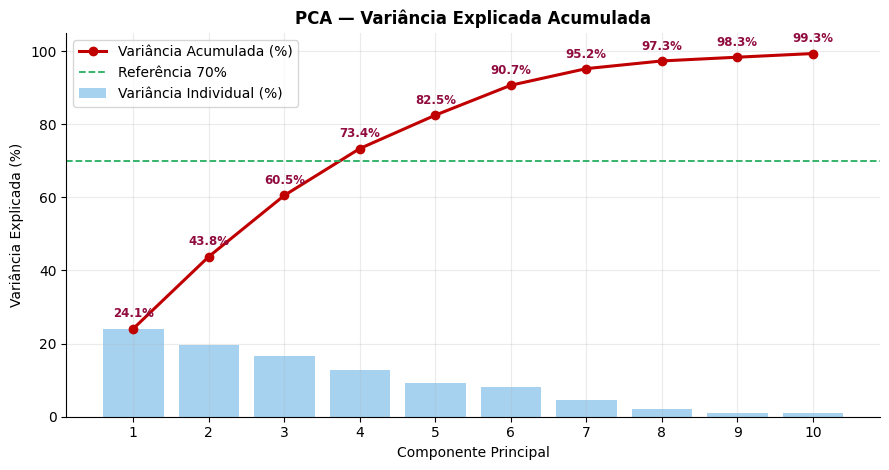

In [51]:
# ==============================================================================
# 3.1 PROJEÇÃO LINEAR PCA (10D) E VARIÂNCIA EXPLICADA ACUMULADA
# ==============================================================================
X_pca_10d, pca_10d = projetar_pca(X_tratado, n_components=10, random_state=RANDOM_STATE)
plot_pca_variancia_acumulada(
    pca_10d,
    nome_arquivo='01_pca_variancia_acumulada.png' if SALVAR_FIGURAS else None,
    save_dir=fig_dir_arg,
)
plt.show()

In [52]:
# ==============================================================================
# 3.2 PROJEÇÕES NÃO-LINEARES UMAP BASE (10D PARA CLUSTERIZAR + 2D PARA VISUALIZAR)
# ==============================================================================
# UMAP 10D base (compactado para clusterização: min_dist=0.0)
X_umap_10d, umap_10d = projetar_umap(
    X_tratado,
    n_components=10,
    n_neighbors=40,
    min_dist=0.0,
    random_state=RANDOM_STATE,
)

# UMAP 2D (espalhado apenas para gráficos: min_dist=0.1)
X_umap_2d, umap_2d = projetar_umap(
    X_tratado,
    n_components=2,
    n_neighbors=40,
    min_dist=0.1,
    random_state=RANDOM_STATE,
)

UMAP (10D | n_neighbors=40, min_dist=0.0) concluído: shape (20663, 10)
UMAP (2D | n_neighbors=40, min_dist=0.1) concluído: shape (20663, 2)


---
## 4.0 Baseline Particional — K-Means (Varredura de $K \in [2, 12]$)

Avaliamos partições convexas nos dois espaços latentes (`X_pca_10d` e `X_umap_10d`) usando:
- **Inércia (Cotovelo / Elbow):** queda marginal da variância intra-cluster;
- **Silhouette Score ($\uparrow$)** — calculado com **subsample de 10.000 pontos (10k)** —, **Davies-Bouldin ($\downarrow$)** e **Calinski-Harabasz ($\uparrow$)** em 100% dos pontos.

In [53]:
# ==============================================================================
# 4.1 VARREDURA K-MEANS EM PCA (10D)
# Nota: Silhouette utiliza subsample de 10.000 (10k) pontos (SUBSAMPLE_SILHOUETTE)
# ==============================================================================
K_RANGE = range(2, 13)

df_km_pca = avaliar_kmeans_range(X_pca_10d, k_range=K_RANGE, sample_size=SUBSAMPLE_SILHOUETTE, random_state=RANDOM_STATE)
display(df_km_pca.style.format({'Inercia': '{:,.1f}', 'Silhouette': '{:.4f}', 'Davies_Bouldin': '{:.4f}', 'Calinski_Harabasz': '{:,.1f}'}))

,K,Inercia,Silhouette,Davies_Bouldin,Calinski_Harabasz
0,2,"852,507,518.1",0.3889,1.3315,"4,971.2"
1,3,"708,881,058.5",0.4254,1.1788,"5,082.0"
2,4,"610,380,543.5",0.4494,1.0481,"5,045.9"
3,5,"521,100,391.2",0.4524,0.9597,"5,317.4"
4,6,"465,213,460.5",0.4580,0.9120,"5,261.0"
5,7,"415,339,785.6",0.4729,0.9254,"5,323.8"
6,8,"390,488,114.9",0.3359,1.0372,"5,041.2"
7,9,"363,908,490.1",0.3494,0.9821,"4,921.6"
8,10,"343,583,470.2",0.2547,1.0789,"4,769.1"
9,11,"318,698,136.5",0.4241,0.9737,"4,788.4"


In [54]:
# ==============================================================================
# 4.2 VARREDURA K-MEANS EM UMAP (10D)
# Nota: Silhouette utiliza subsample de 10.000 (10k) pontos (SUBSAMPLE_SILHOUETTE)
# ==============================================================================
df_km_umap = avaliar_kmeans_range(X_umap_10d, k_range=K_RANGE, sample_size=SUBSAMPLE_SILHOUETTE, random_state=RANDOM_STATE)
display(df_km_umap.style.format({'Inercia': '{:,.1f}', 'Silhouette': '{:.4f}', 'Davies_Bouldin': '{:.4f}', 'Calinski_Harabasz': '{:,.1f}'}))

,K,Inercia,Silhouette,Davies_Bouldin,Calinski_Harabasz
0,2,"1,054,100.4",0.2505,1.4334,"6,238.1"
1,3,"828,115.1",0.2965,1.4322,"6,789.0"
2,4,"702,805.5",0.3407,1.4685,"6,560.6"
3,5,"596,169.9",0.3709,1.3993,"6,724.1"
4,6,"492,945.4",0.4114,1.1417,"7,370.4"
5,7,"422,559.4",0.4327,0.9520,"7,738.2"
6,8,"369,845.2",0.4507,0.9427,"7,998.3"
7,9,"322,699.2",0.4710,0.8881,"8,397.8"
8,10,"277,274.9",0.4929,0.8034,"9,063.2"
9,11,"242,502.5",0.4954,0.8056,"9,622.1"


### 4.3 Curva do Cotovelo e Métricas Internas (PCA 10D vs. UMAP 10D)

Comparamos primeiro a queda da inércia (Elbow) nos dois espaços e, em seguida, inspecionamos separadamente Silhouette, Davies-Bouldin e Calinski-Harabasz.

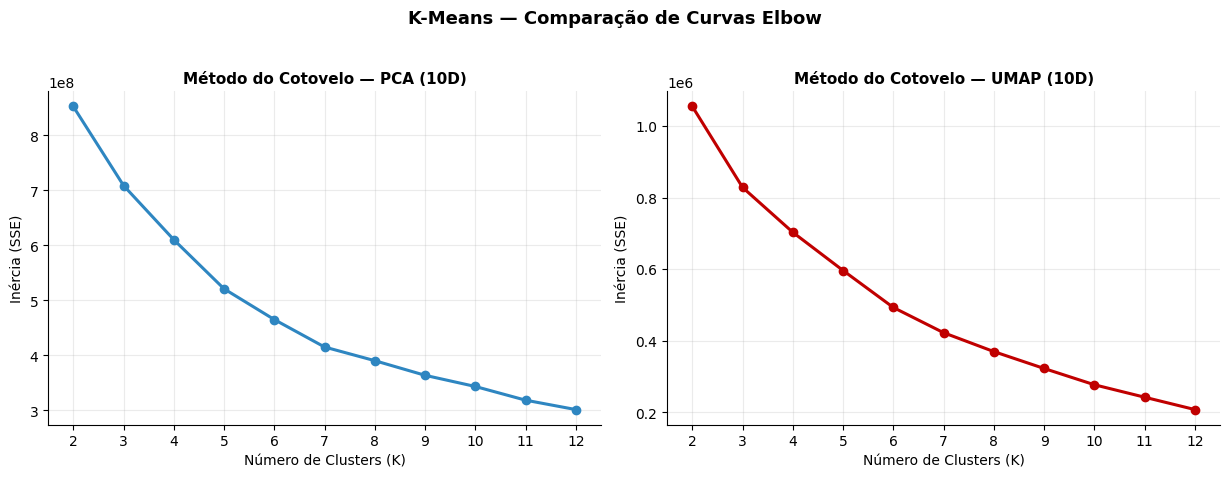

In [55]:
# ==============================================================================
# 4.3a COMPARAÇÃO DE CURVAS ELBOW (PCA 10D vs UMAP 10D)
# ==============================================================================
plot_elbow_comparativo(
    {'PCA (10D)': df_km_pca, 'UMAP (10D)': df_km_umap},
    nome_arquivo='02_kmeans_elbow_comparativo.png' if SALVAR_FIGURAS else None,
    save_dir=fig_dir_arg,
)
plt.show()

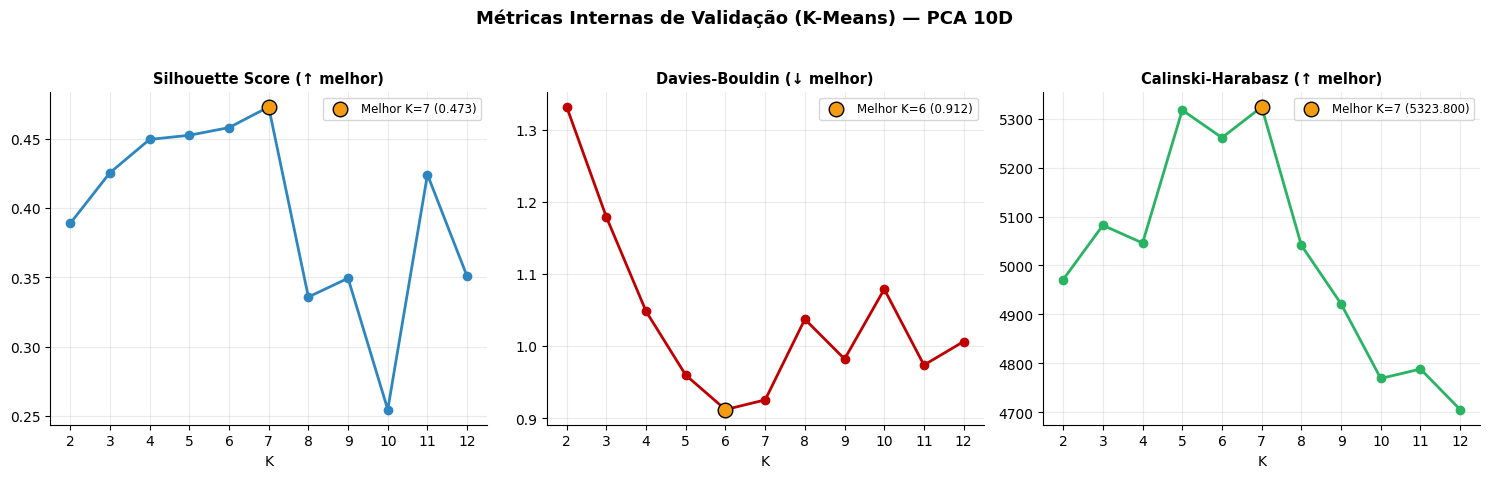

In [56]:
# ==============================================================================
# 4.3b MÉTRICAS INTERNAS K-MEANS — PCA (10D)
# ==============================================================================
plot_metricas_validacao(
    df_km_pca,
    titulo_espaco='PCA 10D',
    nome_arquivo='03_kmeans_metricas_pca.png' if SALVAR_FIGURAS else None,
    save_dir=fig_dir_arg,
)
plt.show()

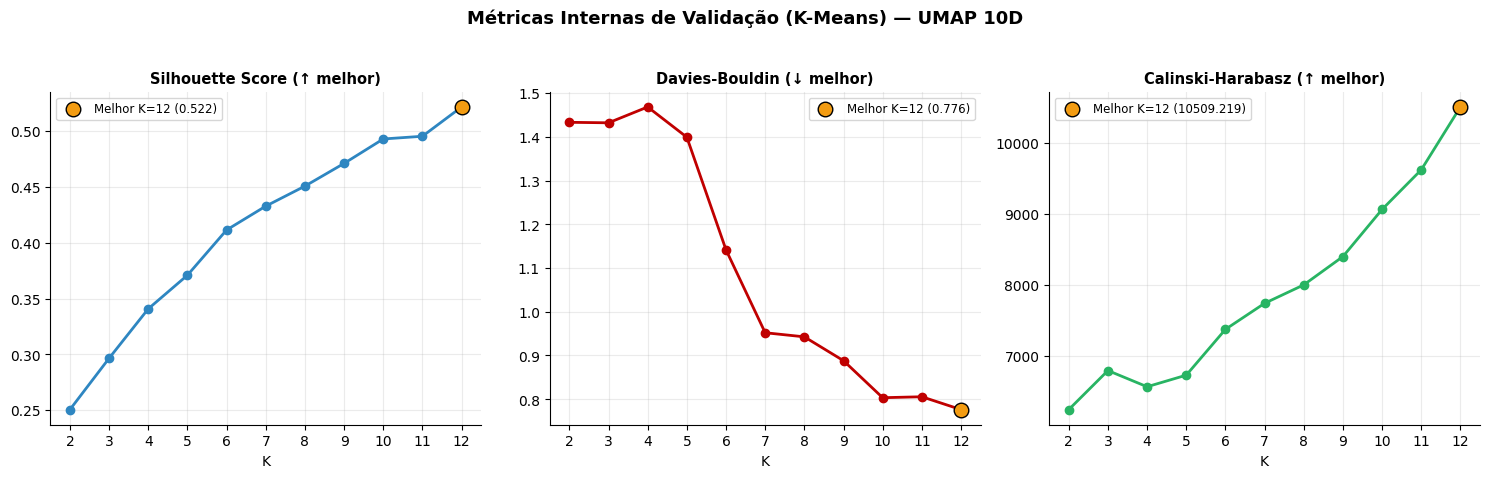

In [57]:
# ==============================================================================
# 4.3c MÉTRICAS INTERNAS K-MEANS — UMAP (10D)
# ==============================================================================
plot_metricas_validacao(
    df_km_umap,
    titulo_espaco='UMAP 10D',
    nome_arquivo='04_kmeans_metricas_umap.png' if SALVAR_FIGURAS else None,
    save_dir=fig_dir_arg,
)
plt.show()

---
## 5.0 Modelo Final (K-Means $K=10$), Perfilamento e Assinatura das Quadrilhas

Com base nas curvas de validação da Seção 4.0 em `UMAP (10D)`, fixamos **$K=10$** para segmentar as fraudes em arquétipos operacionais distintos. Em seguida, cruzamos os clusters com os dados originais (em **100% das fraudes**, reconvertendo valores financeiros quando necessário) para diagnosticar o *modus operandi* de cada grupo.

In [69]:
# ==============================================================================
# 5.1 TREINO DO K-MEANS FINAL (K=10 NO UMAP 10D) E TABELA DE PERFILAMENTO
# ==============================================================================
K_ESCOLHIDO = 10

kmeans_final = KMeans(n_clusters=K_ESCOLHIDO, init='k-means++', n_init=20, random_state=RANDOM_STATE)
df_fraude['cluster'] = kmeans_final.fit_predict(X_umap_10d)

df_perfil_negocio = gerar_perfil_fraude_clusters(
    df_fraude,
    col_cluster='cluster',
    ignorar_ruido=False,
).sort_values('Prejuizo_Total_USD', ascending=False).reset_index(drop=True)

print('=' * 95)
print(f'PERFILAMENTO FINANCEIRO E OPERACIONAL POR CLUSTER DE FRAUDE (K={K_ESCOLHIDO})')
print('=' * 95)
display(df_perfil_negocio.style.format({
    'Prejuizo_Total_USD': '${:,.2f}',
    'Ticket_Medio_USD': '${:,.2f}',
    'Ticket_Mediano_USD': '${:,.2f}',
}))

Nota: `TransactionAmt` estava em escala `log1p`; valores USD foram reconvertidos via `expm1`.
PERFILAMENTO FINANCEIRO E OPERACIONAL POR CLUSTER DE FRAUDE (K=10)


,Cluster,N_Fraudes,%_Fraudes,Prejuizo_Total_USD,Ticket_Medio_USD,Ticket_Mediano_USD,ProductCD_Moda,card6_limpo_Moda,device_brand_Moda,P_emaildomain_Moda,Media_tr_null_count,Media_id_null_count,Media_C2,Media_C5,Media_C8,Media_C12
0,Cluster 1,2749,13.300000,"$487,782.57",$177.44,$97.00,W (80.2%),debit (55.3%),missing (85.3%),gmail.com (41.5%),181.790000,2.950000,19.370000,1.930000,9.680000,9.280000
1,Cluster 4,4147,20.070000,"$438,175.84",$105.66,$58.41,C (55.3%),credit (56.7%),Windows (33.2%),gmail.com (56.9%),96.730000,2.650000,68.200000,0.000000,33.090000,25.380000
2,Cluster 2,1449,7.010000,"$414,982.48",$286.39,$141.00,W (100.0%),debit (57.8%),missing (100.0%),gmail.com (34.6%),173.630000,nan,6.700000,3.490000,0.000000,0.450000
3,Cluster 6,1213,5.870000,"$362,048.50",$298.47,$141.00,W (100.0%),debit (61.4%),missing (100.0%),gmail.com (42.0%),175.370000,nan,4.830000,2.990000,0.000000,0.100000
4,Cluster 9,1334,6.460000,"$297,538.05",$223.04,$117.00,W (100.0%),debit (67.7%),missing (100.0%),gmail.com (44.2%),174.380000,nan,3.010000,1.390000,0.000000,0.090000
5,Cluster 7,1688,8.170000,"$280,716.23",$166.30,$150.00,H (38.2%),credit (64.3%),Apple (42.8%),gmail.com (51.5%),116.390000,2.370000,28.300000,0.000000,11.220000,2.290000
6,Cluster 8,2722,13.170000,"$248,658.38",$91.35,$44.11,C (77.1%),credit (55.2%),Other (36.0%),gmail.com (57.4%),114.770000,2.870000,37.300000,0.880000,10.960000,11.030000
7,Cluster 0,1473,7.130000,"$234,129.66",$158.95,$100.00,W (94.5%),debit (81.9%),missing (94.9%),gmail.com (34.9%),182.030000,2.780000,9.380000,5.240000,0.730000,0.740000
8,Cluster 3,3106,15.030000,"$168,231.96",$54.16,$32.21,C (95.2%),credit (59.3%),Other (42.6%),gmail.com (51.3%),93.880000,2.830000,134.150000,0.000000,72.520000,70.020000
9,Cluster 5,782,3.780000,"$151,581.31",$193.84,$92.00,W (100.0%),debit (76.5%),missing (100.0%),gmail.com (38.5%),174.130000,nan,6.330000,3.980000,0.000000,0.170000


### 5.2 Volumetria e Mapa Topológico dos Clusters (`UMAP 2D`)

Visualizamos primeiro a distribuição de volume por cluster (em **100% das fraudes**) e depois o mapa interativo no espaço `UMAP 2D` (**subsample visual de 15.000 / 15k pontos**).

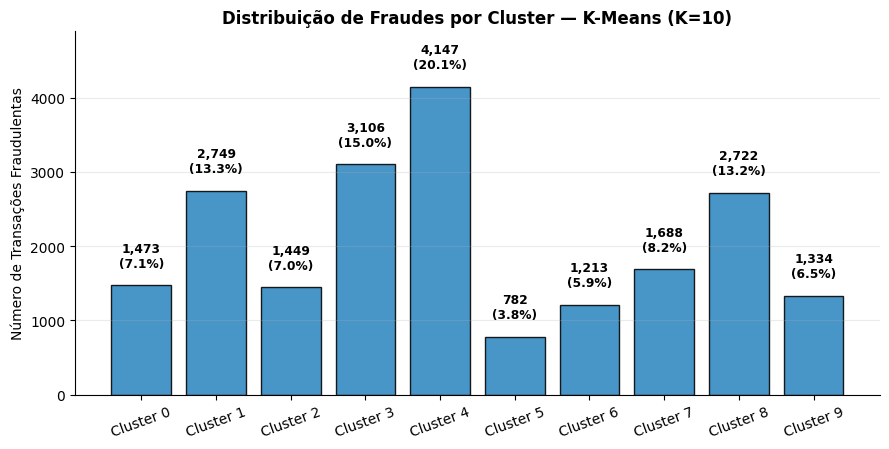

In [70]:
# ==============================================================================
# 5.2a DISTRIBUIÇÃO DE VOLUMES POR CLUSTER (100% DAS FRAUDES)
# ==============================================================================
plot_distribuicao_clusters(
    df_fraude['cluster'],
    titulo=f'Distribuição de Fraudes por Cluster — K-Means (K={K_ESCOLHIDO})',
    nome_arquivo='05_distribuicao_clusters_kmeans.png' if SALVAR_FIGURAS else None,
    save_dir=fig_dir_arg,
)
plt.show()

In [73]:
# ==============================================================================
# 5.2b PROJEÇÃO INTERATIVA UMAP 2D (SUBSAMPLE VISUAL DE 15k PONTOS)
# ==============================================================================
fig_umap_2d = plot_clusters_2d_plotly(
    X_umap_2d,
    df_fraude['cluster'],
    titulo=f'Projeção UMAP 2D das Fraudes — K-Means (K={K_ESCOLHIDO} | subsample 15k)',
    hover_df=df_fraude,
    sample_plot=SUBSAMPLE_PLOT_2D,
    random_state=RANDOM_STATE,
    nome_arquivo='06_umap_2d_kmeans.html' if SALVAR_FIGURAS else None,
    save_dir=fig_dir_arg,
)
fig_umap_2d.show()

### 5.3 Assinatura Numérica (*Heatmap* de Z-Score)

Comparamos o desvio relativo (Z-Score) das principais variáveis financeiras, contagens (`C*`), nulos (`tr_null_count`, `id_null_count`) e atrasos ancorados (`D*_ancora`) para evidenciar o que diferencia cada quadrilha.

Aqui está o markdown ajustado e otimizado. A estrutura foi refinada para torná-la mais profissional, executiva e pronta para ser apresentada a *stakeholders*. 

As principais melhorias incluem: padronização das listas de características, uso de *blockquotes* (citações) para destacar as ações recomendadas, e a adição de uma **Tabela Resumo (Matriz de Arquétipos)** no início, o que facilita a leitura rápida por parte da diretoria e times de risco.

***

# 🛡️ Mapeamento de Perfis de Fraude (Modus Operandi)

**Metodologia:** Análise de Clusters via K-Means (K=10) sobre Projeção UMAP 10D.
**Amostra:** 20.663 transações fraudulentas.

A aplicação de redução de dimensionalidade não-linear (UMAP) aliada à clusterização particional permitiu segmentar a base em 10 clusters matematicamente coesos. 

Para fins de Inteligência de Risco e criação de regras de negócio, os 10 clusters foram consolidados em **4 Grandes Grupos de Ataque (Arquétipos)**, baseados no comportamento financeiro, velocidade da transação e rastros digitais.

---

### 📊 Matriz Resumo de Arquétipos

| Arquétipo | Clusters | Representatividade | Produto Alvo | Ticket Médio | Assinatura Principal |
| :--- | :---: | :---: | :---: | :---: | :--- |
| **1. Botnets** | 3, 4, 8 | ~48,2% | Digital (C) | Muito Baixo ($54 - $105) | Velocidade extrema (C2 > 37) |
| **2. Hit and Run** | 2, 5, 6, 9 | ~23,0% | Varejo (W) | Alto ($193 - $298) | Device Info oculto (Missing) |
| **3. ATO Premium** | 7 | ~8,1% | Hotel/High-Risk (H) | Médio ($166) | Ecossistema Apple / Crédito |
| **4. Clássica** | 0, 1 | ~20,4% | Varejo (W) | Alto ($97 - $100) | Débito / Comportamento na Média |

---

### 💻 Grupo 1: Ataques Automatizados e Card Testing (Botnets)
**Clusters:** 3, 4 e 8 | **Representatividade:** ~48,2% do volume total

O grupo de maior volumetria transacional. Caracteriza-se por ataques em massa via scripts ou botnets, com o objetivo de testar lotes de cartões roubados ou realizar micro-compras não rastreáveis.

*   **Produto Alvo:** Quase exclusivo de bens e serviços digitais (`ProductCD == 'C'`), onde a liquidação é instantânea e não há endereço físico de entrega.
*   **Velocidade (Contagens 'C'):** Anormalmente altas. Variáveis como `C2` (frequência) explodem para médias entre **37 e 134**, indicando dezenas de transações seguidas do mesmo IP/dispositivo em curtíssimo espaço de tempo.
*   **Ticket Financeiro:** Muito baixo. Médias entre **$54 e $105** (medianas entre $32 e $58).
*   **Rastros Digitais:** Presença massiva de e-mails `gmail.com` e dispositivos categorizados como `Windows` ou `Other`.

> 💡 **Ação Recomendada (Prevenção):** Como o ticket é muito baixo, um threshold de bloqueio baseado em valor falhará. A defesa deve focar em **Velocity Checks**, implementando *rate-limiting* severo para múltiplos cartões tentando comprar no mesmo dispositivo/IP em menos de 24 horas.

---

### 🏃 Grupo 2: Hit and Run — Fraude de Alto Valor no Varejo
**Clusters:** 2, 5, 6 e 9 | **Representatividade:** ~23,0% do volume (Prejuízo > US$ 1,2 milhão)

O oposto do Grupo 1. O fraudador "artesanal" realiza poucas tentativas, mas busca extrair o máximo de valor financeiro em uma única transação bem-sucedida.

*   **Produto Alvo:** 100% focado no varejo tradicional (`ProductCD == 'W'`), indicando compra de bens físicos de alto valor (eletrônicos, joias, etc.).
*   **Velocidade:** Fraude de "tiro único". As contagens `C` são baixíssimas (próximas de 0 a 6). Não há repetição frenética.
*   **Ticket Financeiro:** Os mais altos da base. Médias entre **$193 e $298**. O fraudador maximiza o limite do cartão antes que o titular perceba.
*   **Rastros Digitais (Evasão):** Em 100% dos casos, a informação do dispositivo é *missing* (`id_null_count = NaN`). Indica que o fraudador mascara ativamente sua *device fingerprint* ou usa canais sem telemetria.

> 💡 **Ação Recomendada (Prevenção):** Tolerância zero para alto ticket sem rastro digital. Compras do produto W acima de **$140** com *Device Info* oculto devem ser enviadas diretamente para autenticação forte (ex: 3DSecure ou envio de SMS para o portador).

---

### 🍏 Grupo 3: Account Takeover (ATO) e Fraude Premium
**Cluster:** 7 | **Representatividade:** ~8,1% do volume

Arquétipo específico e sofisticado que afeta produtos/serviços que exigem maior validação, sugerindo o roubo da conta de bons clientes.

*   **Produto Alvo:** Predominância forte do produto `H` (**38,2%**). No ecossistema de pagamentos, bens 'H' (High-risk/Hotel) demandam cadastros mais rigorosos.
*   **Meio de Pagamento:** Maior uso de cartões de **Crédito (64,3%)**, diferente do resto da base que foca em Débito.
*   **Rastros Digitais:** Forte predominância do ecossistema **Apple (42,8%)**. O fraudador utiliza dispositivos *premium* (roubados, clonados ou emulados) para se passar por um cliente de alto padrão.
*   **Velocidade e Ticket:** Ticket médio considerável (**$166**) e velocidade moderada (`C2` média de 28).

> 💡 **Ação Recomendada (Prevenção):** Combate a ATO (Sequestro de Conta). Como o fraudador já está logado na conta da vítima, verificar apenas a senha falha. Adotar **Biometria Comportamental** (análise de digitação/mouse) e monitorar mudanças bruscas no endereço de entrega padrão da conta.

---

### 🛒 Grupo 4: A Fraude Clássica / Limbo Operacional
**Clusters:** 0 e 1 | **Representatividade:** ~20,4% do volume (Prejuízo > US$ 720 mil)

Engloba a "massa" de fraudes generalizadas que não possuem assinaturas extremas (como botnets ou hit and run), operando perigosamente perto da média dos clientes legítimos.

*   **Características:** Dominam compras físicas de varejo (`W`), quase totalmente em cartões de Débito.
*   **Ticket e Rastros:** Tickets altos (mediana entre **$97 e $100**), uso massivo de `gmail.com` e falta de identificação do dispositivo (*missing*).
*   **O Desafio:** Seus indicadores comportamentais (`C`, `D`) não explodem. Regras fixas `if/then` têm dificuldade de pará-los sem gerar muitos Falsos Positivos.

> 💡 **Ação Recomendada (Prevenção):** É para este grupo que o **Modelo de Machine Learning (LightGBM/XGBoost/CatBoost) brilha**. Enquanto regras humanas pegam os Grupos 1 e 2 facilmente pelos extremos, os modelos supervisionados são essenciais para captar os micro-sinais (árvores de decisão) que separam a fraude clássica de uma compra legítima neste quadrante de "comportamento na média".

---
### 🎯 Conclusão Estratégica
A segmentação comprova a necessidade de uma **arquitetura de defesa em camadas (Defense in Depth)**:
1.  **Regras de Negócio (Velocity & Device):** Eficazes e imediatas para os Grupos 1 e 2 (extremamente baratos de implementar e bloqueiam quase metade do volume).
2.  **Autenticação Reforçada (Step-up):** Para o Grupo 3, mitigando o ATO.
3.  **Modelagem Preditiva (ML):** Obrigatória para o Grupo 4, atuando como a camada de inteligência que captura o que as regras fixas não conseguem ver, reduzindo o atrito com clientes legítimos.

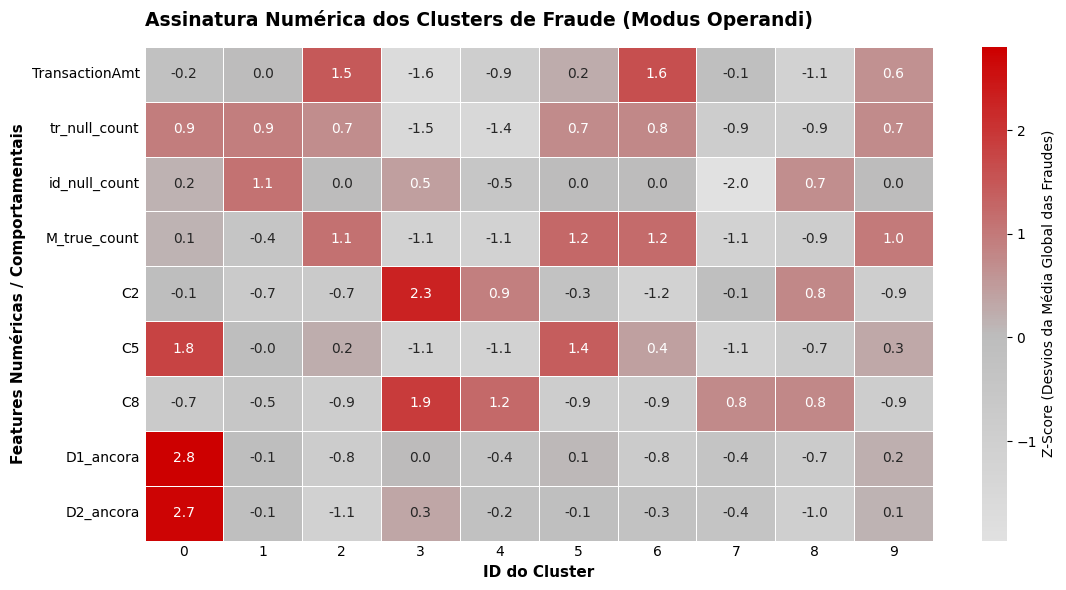

In [72]:
# ==============================================================================
# 5.3 HEATMAP DE Z-SCORE DAS FEATURES COMPORTAMENTAIS CONTÍNUAS
# ==============================================================================
features_continuas = [
    'TransactionAmt', 'tr_null_count', 'id_null_count', 'M_true_count',
    'C1', 'C2', 'C5', 'C8', 'C13', 'C14',
    'D1_ancora', 'D2_ancora', 'D4_ancora',
]

plot_heatmap_zscore_clusters(
    df_fraude,
    col_cluster='cluster',
    features_continuas=features_continuas,
    titulo='Assinatura Numérica dos Clusters de Fraude (Modus Operandi)',
    ignorar_ruido=False,
    nome_arquivo='07_heatmap_zscore_clusters.png' if SALVAR_FIGURAS else None,
    save_dir=fig_dir_arg,
)
plt.show()